Training images: D:\B. Disease Grading\1. Original Images\a. Training Set
Testing images: D:\B. Disease Grading\1. Original Images\b. Testing Set
Training images: 413
Testing images: 103
Total images: 516
Image: IDRiD_001.jpg
Shape: (2848, 4288, 3)
Data type: uint8


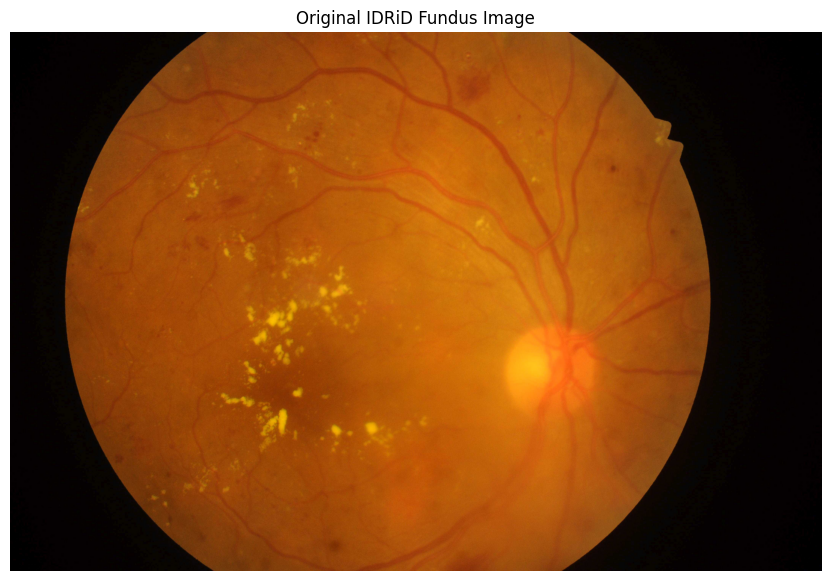

In [8]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset path
BASE_DIR = r"D:\B. Disease Grading"

TRAIN_IMG_DIR = os.path.join(
    BASE_DIR, "1. Original Images", "a. Training Set"
)

TEST_IMG_DIR = os.path.join(
    BASE_DIR, "1. Original Images", "b. Testing Set"
)

print("Training images:", TRAIN_IMG_DIR)
print("Testing images:", TEST_IMG_DIR)
train_images = sorted(Path(TRAIN_IMG_DIR).glob("*.jpg"))
test_images = sorted(Path(TEST_IMG_DIR).glob("*.jpg"))

print("Training images:", len(train_images))
print("Testing images:", len(test_images))
print("Total images:", len(train_images) + len(test_images))

# ---------------------------------------------------------------
# 3. Load one sample image
# ---------------------------------------------------------------

sample_name = train_files[0]
sample_path = os.path.join(TRAIN_IMG_DIR, sample_name)

image_bgr = cv2.imread(sample_path)

if image_bgr is None:
    raise ValueError("Image could not be loaded.")

# Convert BGR → RGB for displaying with matplotlib
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print("Image:", sample_name)
print("Shape:", image_rgb.shape)
print("Data type:", image_rgb.dtype)
# ---------------------------------------------------------------
# 4. Display original fundus image
# ---------------------------------------------------------------

plt.figure(figsize=(12, 7))

plt.imshow(image_rgb)
plt.title("Original IDRiD Fundus Image")
plt.axis("off")

plt.show()

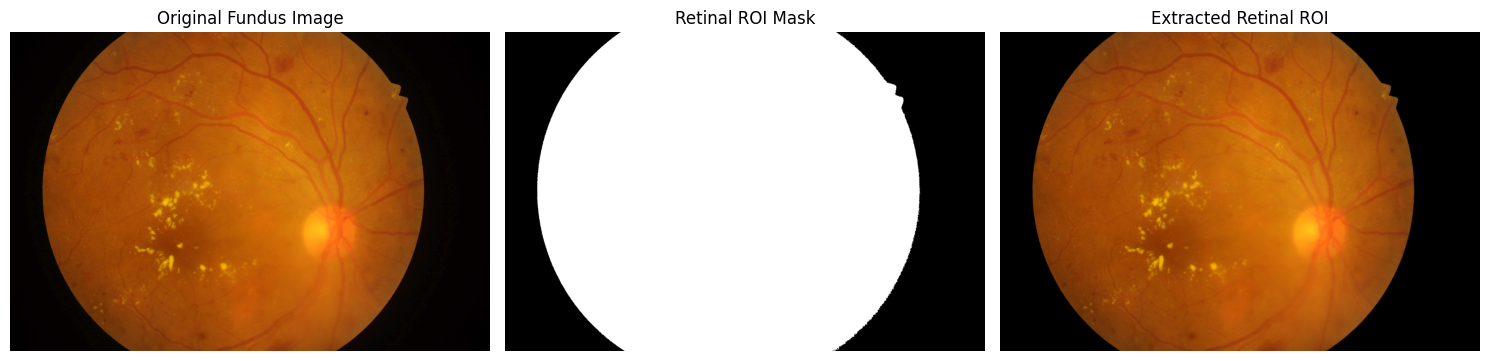

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the sample image
image_path = r"D:\B. Disease Grading\1. Original Images\a. Training Set\IDRiD_001.jpg"

img = cv2.imread(image_path)

# Convert BGR to RGB for displaying
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Threshold to separate retinal region from dark background
_, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

# Find contours
contours, _ = cv2.findContours(
    thresh,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Select the largest contour
largest_contour = max(contours, key=cv2.contourArea)

# Create an empty mask
roi_mask = np.zeros_like(gray)

# Fill the largest contour
cv2.drawContours(
    roi_mask,
    [largest_contour],
    -1,
    255,
    thickness=cv2.FILLED
)

# Apply the ROI mask to the original image
roi = cv2.bitwise_and(img_rgb, img_rgb, mask=roi_mask)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Fundus Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(roi_mask, cmap="gray")
plt.title("Retinal ROI Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(roi)
plt.title("Extracted Retinal ROI")
plt.axis("off")

plt.tight_layout()
plt.show()

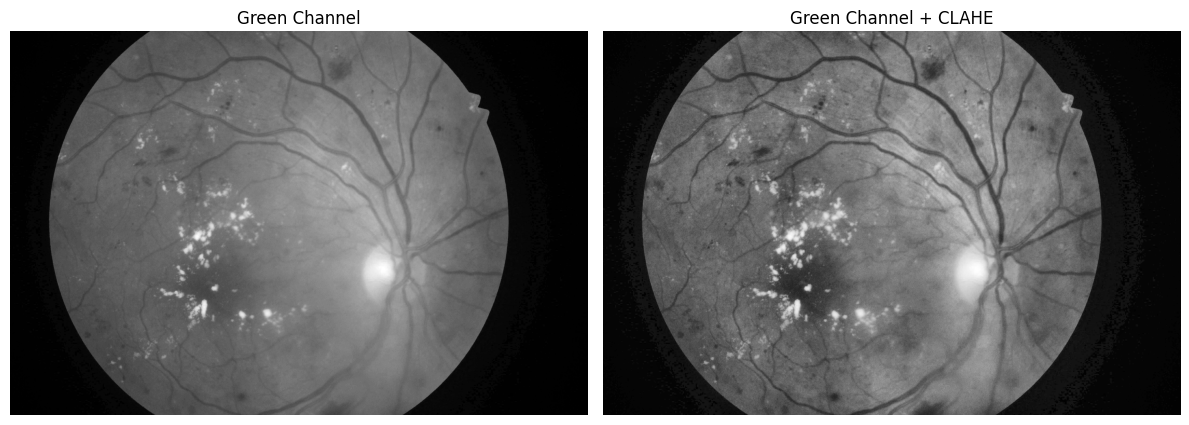

In [10]:
# Extract green channel
green = img_rgb[:, :, 1]

# Apply CLAHE
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

green_clahe = clahe.apply(green)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(green, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(green_clahe, cmap="gray")
plt.title("Green Channel + CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

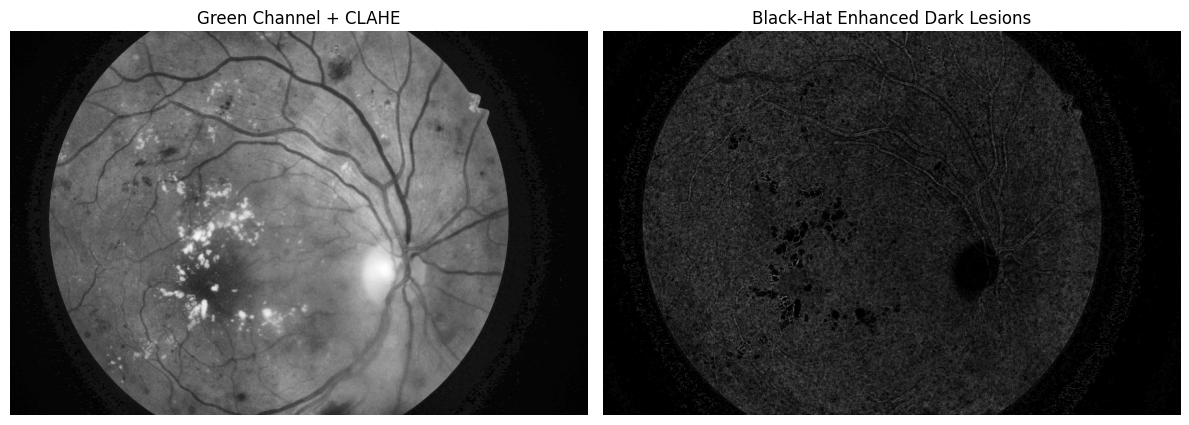

In [11]:
# Morphological Black-Hat Transformation
# Helps highlight small dark structures against a brighter background

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (15, 15)
)

blackhat = cv2.morphologyEx(
    green_clahe,
    cv2.MORPH_BLACKHAT,
    kernel
)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(green_clahe, cmap="gray")
plt.title("Green Channel + CLAHE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blackhat, cmap="gray")
plt.title("Black-Hat Enhanced Dark Lesions")
plt.axis("off")

plt.tight_layout()
plt.show()

Black-hat intensity statistics
--------------------------------
Minimum : 0
Maximum : 98
Mean    : 10.968663958950224
Median  : 10.0

Percentiles:
90% : 23.00
95% : 27.00
97% : 30.00
98% : 32.00
99% : 36.00
99.5% : 39.00
99.9% : 47.00


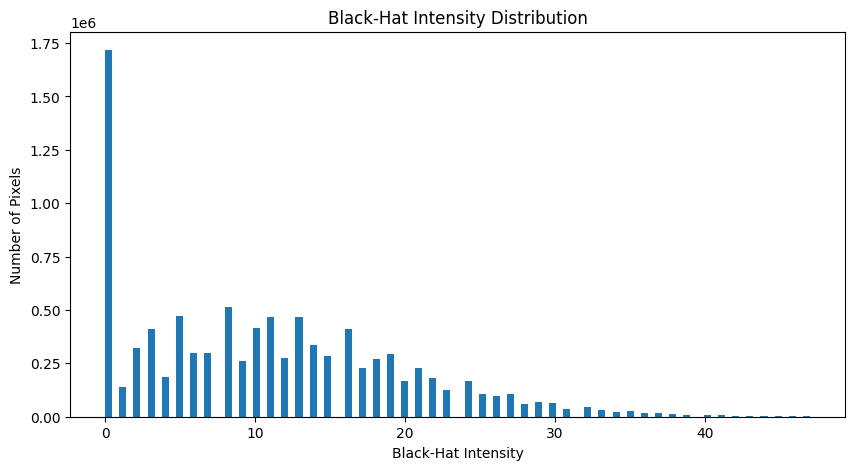

In [ ]:
# Analyze black-hat intensity distribution

# Create a simple retinal mask
# Pixels brighter than 10 are considered part of the retinal field
retinal_mask = green_clahe > 10

# Get black-hat values only inside the retinal region
blackhat_values = blackhat[retinal_mask]

# Calculate useful percentiles
percentiles = [90, 95, 97, 98, 99, 99.5, 99.9]

print("Black-hat intensity statistics")
print("--------------------------------")
print("Minimum :", blackhat_values.min())
print("Maximum :", blackhat_values.max())
print("Mean    :", blackhat_values.mean())
print("Median  :", np.median(blackhat_values))

print("\nPercentiles:")
for p in percentiles:
    print(f"{p}% : {np.percentile(blackhat_values, p):.2f}")
# Plot the black-hat intensity histogram

plt.figure(figsize=(10, 5))

plt.hist(
    blackhat_values,
    bins=100,
    range=(0, np.percentile(blackhat_values, 99.9))
)
plt.xlabel("Black-Hat Intensity")
plt.ylabel("Number of Pixels")
plt.title("Black-Hat Intensity Distribution")

plt.show()

In [15]:
# Test different thresholds for dark-lesion candidates

thresholds = [20, 23, 27, 30, 32, 36]

print("Threshold  | Candidate pixels (%)")
print("--------------------------------")

for t in thresholds:
    candidates = (blackhat >= t) & retinal_mask
    
    percentage = np.mean(candidates) * 100
    count = np.sum(candidates)
    
    print(f"{t:9} | {count:,.0f} ({percentage:.3f}%)")

Threshold  | Candidate pixels (%)
--------------------------------
       20 | 1,649,085 (13.504%)
       23 | 1,073,854 (8.793%)
       27 | 576,004 (4.717%)
       30 | 337,563 (2.764%)
       32 | 238,159 (1.950%)
       36 | 105,652 (0.865%)
